In [2]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import MeanShift

X, y = make_blobs(n_samples= 200, n_features= 2, centers= 3,
                  cluster_std= 0.7, random_state= 0)
meanshift = MeanShift(bandwidth= 0.8)
cluster_labels = meanshift.fit_predict(X)
print('cluster label 유형: ', np.unique(cluster_labels))

cluster label 유형:  [0 1 2 3 4 5]


In [3]:
meanshift = MeanShift(bandwidth=1) 
cluster_labels = meanshift.fit_predict(X)
print('cluster label 유형: ', np.unique(cluster_labels))

cluster label 유형:  [0 1 2]


In [4]:
from sklearn.cluster import estimate_bandwidth

bandwidth = estimate_bandwidth(X)
print(bandwidth)

1.8158484154517098


In [5]:
import pandas as pd

df = pd.DataFrame(data = X, columns= ['ftr1', 'ftr2'])
df['target'] = y

best_bandwidth = estimate_bandwidth(X)

meanshift = MeanShift(bandwidth= best_bandwidth)
cluster_labels = meanshift.fit_predict(X)
print(np.unique(cluster_labels))

[0 1 2]


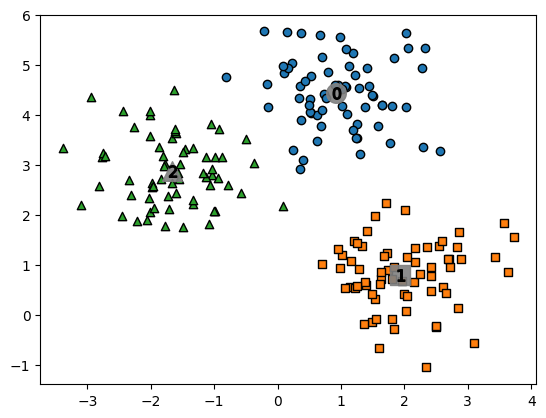

In [7]:
import matplotlib.pyplot as plt

df['meanshift_label'] = cluster_labels
centers = meanshift.cluster_centers_
unique_labels = np.unique(cluster_labels)
markers = ['o', 's', '^', 'x', '*']

for label in unique_labels:
    label_cluster = df[df['meanshift_label'] == label]
    center_x_y = centers[label]
    plt.scatter(x = label_cluster['ftr1'], y= label_cluster['ftr2'],
                edgecolor= 'k', marker = markers[label])
    plt.scatter(x= center_x_y[0], y= center_x_y[1], s= 200, color='gray',
                alpha= 0.9, marker = markers[label])
    plt.scatter(x= center_x_y[0], y= center_x_y[1], s = 70,
                color= 'k', edgecolor= 'k', marker = '$%d$' % label)
plt.show()

In [8]:
print(df.groupby('target')['meanshift_label'].value_counts())

target  meanshift_label
0       0                  67
1       1                  67
2       2                  66
Name: meanshift_label, dtype: int64
